# Part 1 — Hierarchical (two-stage) Monte Carlo sampling

**Question.** We want an expectation over two correlated latent variables,

$$
\mu \;=\; \mathbb{E}_{q(z_1, z_2)}\big[\, \ell(z_1, z_2) \,\big],
\qquad \ell(z_1, z_2) = \log p(x \mid z_1, z_2).
$$

We can sample $(z_1, z_2)$ *jointly*, or *hierarchically*: first $z_1 \sim q(z_1)$, then several
$z_2 \sim q(z_2 \mid z_1)$ for each $z_1$. Both give an unbiased estimator of $\mu$. This notebook
works out **when the hierarchical scheme helps, when it hurts, and by how much**.

The key fact, which Part 2 will contrast with, is that here the inner average enters the estimator
**linearly**. That is why this is *not* "nested Monte Carlo" in the technical sense, even though the
code has two nested loops.

**Contents**
1. The model, and an exact value for $\mu$
2. Two ways to sample the same joint distribution
3. The two-stage estimator is unbiased for every $M$
4. Its variance: the law of total variance
5. Fixed budget, equal costs: $M = 1$ is optimal
6. Unequal costs: the optimal $M$
7. The limit $M \to \infty$: Rao–Blackwellisation
8. Takeaways

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from model import Model

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(2026)

## 1. The model, and an exact value for $\mu$

**Latent variables.** $(z_1, z_2)$ follow a bivariate normal distribution

$$
q(z_1, z_2) = \mathcal{N}\!\left(\begin{bmatrix}\mu_1\\ \mu_2\end{bmatrix},\;
\begin{bmatrix}\sigma_1^2 & \rho\,\sigma_1\sigma_2\\ \rho\,\sigma_1\sigma_2 & \sigma_2^2\end{bmatrix}\right),
\qquad \mu_1=\mu_2=0,\ \sigma_1=\sigma_2=1,\ \rho = 0.5 .
$$

**Observation model.** $x \mid z_1, z_2 \sim \mathcal{N}\big(\phi(z_1,z_2),\, 1\big)$ with
$\phi(z_1,z_2) = z_1^2 + z_2^2$, and we observe $x = 1$. So

$$
\ell(z_1,z_2) = -\tfrac12\log 2\pi \;-\; \tfrac12\big(x - z_1^2 - z_2^2\big)^2 .
$$

**Exact value.** Because $\ell$ is a polynomial in Gaussian variables, $\mu$ has a closed form.
Write $S = z_1^2 + z_2^2$. With standard margins, $\mathbb{E}[z_i^2]=1$, $\mathbb{E}[z_i^4]=3$, and
Isserlis' theorem gives $\mathbb{E}[z_1^2 z_2^2] = 1 + 2\rho^2$. Hence

$$
\mathbb{E}[S] = 2,\qquad
\mathbb{E}[S^2] = 3 + 3 + 2(1+2\rho^2) = 8 + 4\rho^2,
$$

$$
\mu = -\tfrac12\log 2\pi - \tfrac12\big(x^2 - 2x\,\mathbb{E}[S] + \mathbb{E}[S^2]\big)
    = -\tfrac12\log 2\pi - \tfrac12\,(5 + 4\rho^2) \quad (x = 1).
$$

For $\rho = 0.5$ this is $-\tfrac12\log 2\pi - 3 \approx -3.9189$. Having the exact answer means that every
claim below about bias and variance can be checked numerically, not just asserted.

All model code lives in [`model.py`](model.py).

In [2]:
model = Model(rho=0.5, x=1.0)
mu_exact = model.exact_expected_log_lik()
print(f"exact mu               = {mu_exact:.6f}")
print(f"closed form            = {-0.5 * np.log(2 * np.pi) - 0.5 * (5 + 4 * model.rho**2):.6f}")

exact mu               = -3.918939
closed form            = -3.918939


## 2. Two ways to sample the same joint distribution

**Joint (direct) sampling.** Factor $\Sigma = LL^\top$ (Cholesky) and set $z = \mu + L\varepsilon$ with
$\varepsilon \sim \mathcal{N}(0, I_2)$.

**Ancestral (hierarchical) sampling.** Use the factorisation $q(z_1,z_2) = q(z_1)\,q(z_2\mid z_1)$, where
for a bivariate normal

$$
z_2 \mid z_1 \;\sim\; \mathcal{N}\!\Big(\mu_2 + \rho\,\tfrac{\sigma_2}{\sigma_1}(z_1-\mu_1),\;\; \sigma_2^2(1-\rho^2)\Big).
$$

Drawing $z_1 \sim q(z_1)$ and then one $z_2 \sim q(z_2\mid z_1)$ produces an exact draw from the joint.
In fact the two procedures are the same computation: the Cholesky factor of a $2\times2$ covariance is exactly
"sample $z_1$, then $z_2$ given $z_1$". The difference only appears when we **reuse** each $z_1$ for
several $z_2$'s.

In [3]:
n = 200_000
z1_d, z2_d = model.sample_joint(n, rng)
z1_a = model.sample_z1(n, rng)
z2_a = model.sample_z2_given_z1(z1_a, 1, rng)[:, 0]

print("target covariance:\n", model.cov)
print("joint sampling:\n", np.cov(z1_d, z2_d).round(3))
print("ancestral sampling (M = 1):\n", np.cov(z1_a, z2_a).round(3))

target covariance:
 [[1.  0.5]
 [0.5 1. ]]
joint sampling:
 [[1.002 0.5  ]
 [0.5   0.997]]
ancestral sampling (M = 1):
 [[0.999 0.502]
 [0.502 1.002]]


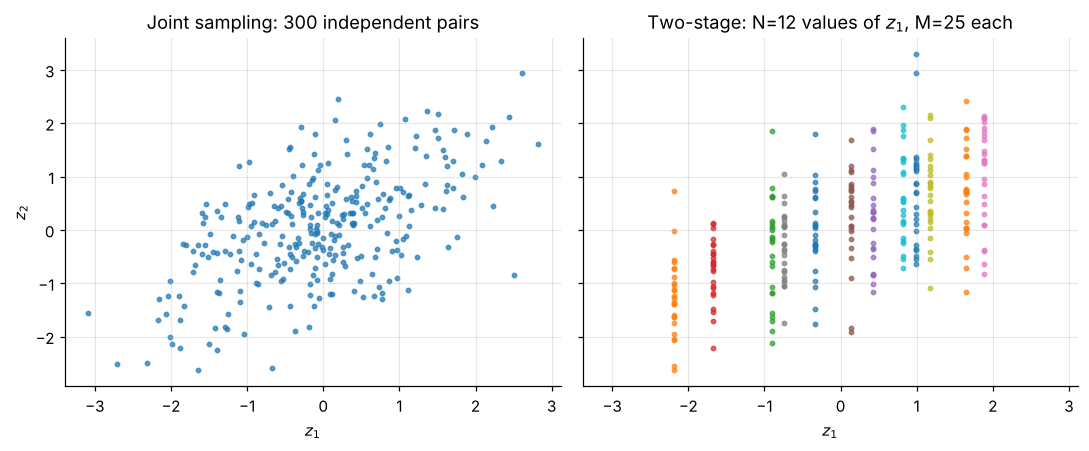

In [4]:
# With M > 1 the *marginal* distribution of each pair is still exactly q(z1, z2),
# but the pairs are no longer independent: pairs sharing a z1 form a "cluster".
N_show, M_show = 12, 25
z1_c = model.sample_z1(N_show, rng)
z2_c = model.sample_z2_given_z1(z1_c, M_show, rng)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
idx = rng.choice(n, N_show * M_show, replace=False)
axes[0].scatter(z1_d[idx], z2_d[idx], s=8, alpha=0.7)
axes[0].set_title(f"Joint sampling: {N_show * M_show} independent pairs")
for i in range(N_show):
    axes[1].scatter(np.full(M_show, z1_c[i]), z2_c[i], s=8, alpha=0.7)
axes[1].set_title(f"Two-stage: N={N_show} values of $z_1$, M={M_show} each")
for ax in axes:
    ax.set_xlabel("$z_1$")
axes[0].set_ylabel("$z_2$")
plt.tight_layout()
plt.show()

Same number of points, very different coverage of the $z_1$ axis. If $\ell$ depends strongly on $z_1$,
the right-hand design will be noisier. Section 4 makes this quantitative.

## 3. The two-stage estimator is unbiased for every $M$

Draw $z_{1,i} \sim q(z_1)$ for $i=1,\dots,N$ and, for each $i$, draw $z_{2,ij} \sim q(z_2 \mid z_{1,i})$ for
$j = 1, \dots, M$. The **two-stage estimator** is

$$
\hat\mu_{N,M} \;=\; \frac1N\sum_{i=1}^N \underbrace{\frac1M\sum_{j=1}^M \ell(z_{1,i}, z_{2,ij})}_{\hat g(z_{1,i})}.
$$

Write $g(z_1) = \mathbb{E}[\ell \mid z_1]$. Each inner average satisfies
$\mathbb{E}[\hat g(z_{1,i}) \mid z_{1,i}] = g(z_{1,i})$. By the tower property,

$$
\mathbb{E}[\hat\mu_{N,M}] = \mathbb{E}_{z_1}\big[g(z_1)\big] = \mathbb{E}_{q(z_1,z_2)}[\ell] = \mu .
$$

This uses nothing except linearity: **the outer average is applied directly to the inner average.**
Part 2 breaks exactly this step.

In [5]:
def two_stage(model, N, M, rng):
    """Two-stage estimator of E[log p(x | z1, z2)]: N outer draws, M inner draws each."""
    z1 = model.sample_z1(N, rng)
    z2 = model.sample_z2_given_z1(z1, M, rng)            # shape (N, M)
    return model.log_lik(z1[:, None], z2).mean()


def joint(model, n, rng):
    """Plain Monte Carlo with n independent joint draws."""
    z1, z2 = model.sample_joint(n, rng)
    return model.log_lik(z1, z2).mean()


R = 4000
for M in (1, 10, 100):
    est = np.array([two_stage(model, 50, M, rng) for _ in range(R)])
    se = est.std(ddof=1) / np.sqrt(R)
    print(f"N=50, M={M:>3}:  mean over {R} replicates = {est.mean():.4f} ± {1.96 * se:.4f}   (exact {mu_exact:.4f})")

N=50, M=  1:  mean over 4000 replicates = -3.9230 ± 0.0443   (exact -3.9189)
N=50, M= 10:  mean over 4000 replicates = -3.9344 ± 0.0352   (exact -3.9189)


N=50, M=100:  mean over 4000 replicates = -3.9209 ± 0.0346   (exact -3.9189)


## 4. Its variance: the law of total variance

Split the variance of $\ell$ into a part explained by $z_1$ and a residual:

$$
\underbrace{\operatorname{Var}(\ell)}_{\sigma^2}
\;=\; \underbrace{\operatorname{Var}\big(\mathbb{E}[\ell\mid z_1]\big)}_{\sigma_B^2\ \text{(between)}}
\;+\; \underbrace{\mathbb{E}\big[\operatorname{Var}(\ell\mid z_1)\big]}_{\sigma_W^2\ \text{(within)}} .
$$

The outer draws are independent, so $\operatorname{Var}(\hat\mu_{N,M}) = \operatorname{Var}\big(\hat g(z_1)\big)/N$.
Applying the same decomposition to $\hat g(z_1)$, whose conditional mean is $g(z_1)$ and conditional variance is
$\operatorname{Var}(\ell\mid z_1)/M$, gives

$$
\boxed{\;\operatorname{Var}(\hat\mu_{N,M}) \;=\; \frac{\sigma_B^2}{N} + \frac{\sigma_W^2}{NM}\;}
\qquad\text{versus}\qquad
\operatorname{Var}(\hat\mu^{\text{joint}}_{n}) = \frac{\sigma_B^2 + \sigma_W^2}{n}.
$$

Two consequences:
* Increasing $M$ only reduces the **within** term. The between term $\sigma_B^2/N$ is a floor that only more
  outer samples can lower.
* The $NM$ pairs are not independent. Pairs that share a $z_1$ have correlation
  $\sigma_B^2/\sigma^2$, the *intra-class correlation*. This is the same mathematics as two-stage
  (cluster) sampling in survey statistics.

For our model $\ell$ is a polynomial, so $\sigma_B^2$ and $\sigma_W^2$ can be computed exactly by
Gauss–Hermite quadrature (`model.variance_components()`).

In [6]:
vc = model.variance_components()
sB2, sW2 = vc["between"], vc["within"]
print(f"sigma^2   (total)   = {vc['total']:.4f}")
print(f"sigma_B^2 (between) = {sB2:.4f}")
print(f"sigma_W^2 (within)  = {sW2:.4f}")
print(f"intra-class correlation = {sB2 / vc['total']:.3f}")

sigma^2   (total)   = 107.0000
sigma_B^2 (between) = 59.7734
sigma_W^2 (within)  = 47.2266
intra-class correlation = 0.559


**The original experiment, revisited.** The first version of this repository compared $N=100$, $M=10$ with
$1000$ joint draws and got $-4.30$ versus $-3.66$. The formula above predicts the spread of each estimator:

predicted sd, two-stage (N=100, M=10): 0.803
predicted sd, joint (n=1000):          0.327


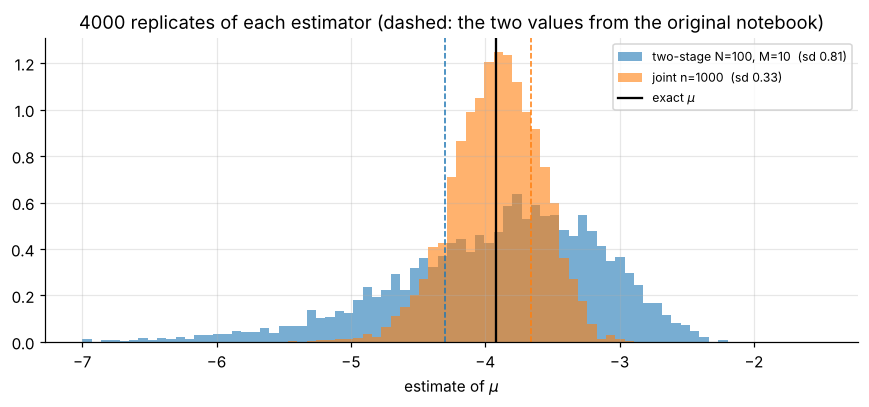

In [7]:
sd_two_stage = np.sqrt(sB2 / 100 + sW2 / 1000)
sd_joint = np.sqrt((sB2 + sW2) / 1000)
print(f"predicted sd, two-stage (N=100, M=10): {sd_two_stage:.3f}")
print(f"predicted sd, joint (n=1000):          {sd_joint:.3f}")

R = 4000
est_ts = np.array([two_stage(model, 100, 10, rng) for _ in range(R)])
est_j = np.array([joint(model, 1000, rng) for _ in range(R)])

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(-7, -1.5, 80)
ax.hist(est_ts, bins=bins, alpha=0.6, density=True, label=f"two-stage N=100, M=10  (sd {est_ts.std():.2f})")
ax.hist(est_j, bins=bins, alpha=0.6, density=True, label=f"joint n=1000  (sd {est_j.std():.2f})")
ax.axvline(mu_exact, color="k", lw=1.5, label=r"exact $\mu$")
for v, c in [(-4.30, "C0"), (-3.66, "C1")]:
    ax.axvline(v, color=c, ls="--", lw=1)
ax.set_xlabel(r"estimate of $\mu$")
ax.set_title(f"{R} replicates of each estimator (dashed: the two values from the original notebook)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Both original numbers are ordinary draws from these distributions. Neither method was wrong. The two-stage
estimator is simply about **2.5× noisier for the same 1000 likelihood evaluations**, because
$\sigma_B^2$ is large here: $\ell$ depends strongly on $z_1$ through $z_1^2$.

## 5. Fixed budget, equal costs: $M = 1$ is optimal

Suppose every likelihood evaluation costs the same and sampling is free, so the budget is $T = NM$
evaluations. Substituting $N = T/M$:

$$
\operatorname{Var}(\hat\mu_{T/M,\,M}) = \frac{M\sigma_B^2 + \sigma_W^2}{T},
$$

which **increases** with $M$. With equal costs, reusing $z_1$ never helps. $M=1$, which is plain joint sampling,
is optimal, and $M = T$ (a single $z_1$!) is the worst possible design.

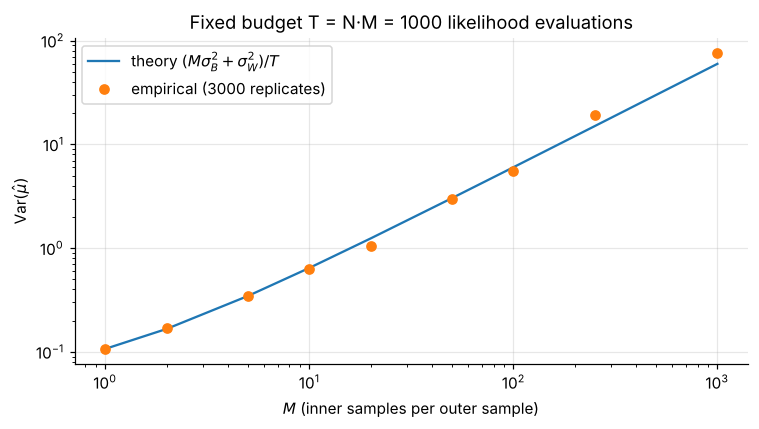

In [8]:
T = 1000
Ms = np.array([1, 2, 5, 10, 20, 50, 100, 250, 1000])
R = 3000
emp = []
for M in Ms:
    est = np.array([two_stage(model, T // M, M, rng) for _ in range(R)])
    emp.append(est.var(ddof=1))
emp = np.array(emp)
theory = (Ms * sB2 + sW2) / T

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(Ms, theory, "-", label=r"theory $(M\sigma_B^2+\sigma_W^2)/T$")
ax.loglog(Ms, emp, "o", label=f"empirical ({R} replicates)")
ax.set_xlabel("$M$ (inner samples per outer sample)")
ax.set_ylabel(r"Var$(\hat\mu)$")
ax.set_title(f"Fixed budget T = N·M = {T} likelihood evaluations")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Unequal costs: the optimal $M$

Hierarchical sampling earns its place when **drawing an outer sample is expensive**. For example, $z_1$
might be a simulator run, an MCMC draw or a costly model fit, while $z_2$ is cheap noise. Let one outer draw
cost $c_1$ and one inner draw plus evaluation cost $c_2$. A total cost $C$ buys $N = C/(c_1 + Mc_2)$ outer
samples, so

$$
\operatorname{Var} \;=\; \frac{1}{C}\,\Big(\sigma_B^2 + \frac{\sigma_W^2}{M}\Big)\big(c_1 + Mc_2\big).
$$

Expanding gives $\sigma_B^2 c_1 + \sigma_W^2 c_2 + M\sigma_B^2 c_2 + \sigma_W^2 c_1/M$. Setting the derivative in
$M$ to zero yields

$$
\boxed{\;M^\star = \sqrt{\frac{c_1}{c_2}\cdot\frac{\sigma_W^2}{\sigma_B^2}}\;}
$$

This is the classical optimal subsample size for two-stage sampling. $M^\star$ grows like the square root of
the cost ratio, and it shrinks when $z_1$ explains most of the variance.

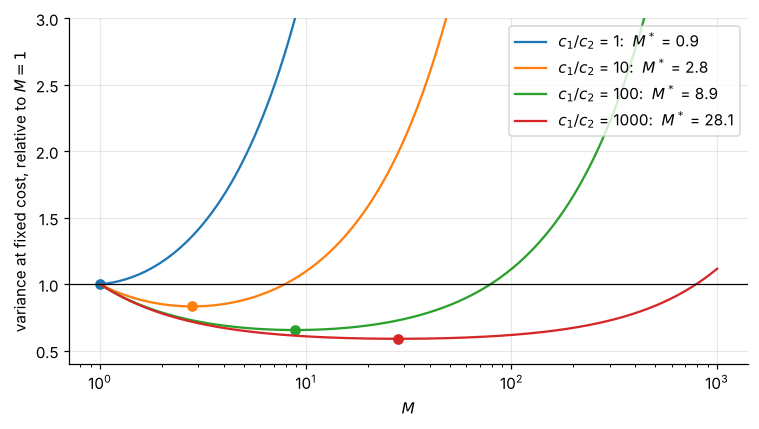

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
Mgrid = np.logspace(0, 3, 300)
for ratio in (1, 10, 100, 1000):
    v = (sB2 + sW2 / Mgrid) * (ratio + Mgrid)          # C * Var, with c2 = 1
    v1 = (sB2 + sW2) * (ratio + 1)                     # value at M = 1
    m_star = np.sqrt(ratio * sW2 / sB2)
    line, = ax.semilogx(Mgrid, v / v1, label=f"$c_1/c_2$ = {ratio}:  $M^*$ = {m_star:.1f}")
    ax.plot(max(m_star, 1), (sB2 + sW2 / max(m_star, 1)) * (ratio + max(m_star, 1)) / v1, "o", color=line.get_color())
ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("$M$")
ax.set_ylabel("variance at fixed cost, relative to $M=1$")
ax.set_ylim(0.4, 3)
ax.legend()
plt.tight_layout()
plt.show()

A quick empirical check with $c_1/c_2 = 100$ and a total cost of $C = 20\,000$ (in units of $c_2$):

In [10]:
ratio, C = 100, 20_000
m_star = int(round(np.sqrt(ratio * sW2 / sB2)))
R = 3000
for M in (1, m_star, 100):
    N = C // (ratio + M)
    est = np.array([two_stage(model, N, M, rng) for _ in range(R)])
    pred = (sB2 / N + sW2 / (N * M))
    print(f"M = {M:>3}  (N = {N:>3}):  empirical var = {est.var(ddof=1):.4f}   predicted = {pred:.4f}")

M =   1  (N = 198):  empirical var = 0.5408   predicted = 0.5404
M =   9  (N = 183):  empirical var = 0.3595   predicted = 0.3553


M = 100  (N = 100):  empirical var = 0.6126   predicted = 0.6025


## 7. The limit $M \to \infty$: Rao–Blackwellisation

As $M\to\infty$ the inner average $\hat g(z_1)$ converges to $g(z_1) = \mathbb{E}[\ell \mid z_1]$ and the within
term vanishes. If $g$ is **available in closed form**, we can take that limit for free and use

$$
\hat\mu^{\text{RB}}_N = \frac1N \sum_{i=1}^N g(z_{1,i}),
\qquad \operatorname{Var}\big(\hat\mu^{\text{RB}}_N\big) = \frac{\sigma_B^2}{N} \;\le\; \frac{\sigma^2}{N}.
$$

This is **conditional Monte Carlo**, or Rao–Blackwellisation: integrate out analytically whatever you can, and
sample only the rest. Here $z_2 \mid z_1$ is Gaussian and $\ell$ is quadratic in $z_2^2$, so with
$a = x - z_1^2$, $m = \mathbb{E}[z_2\mid z_1]$ and $s^2 = \operatorname{Var}(z_2\mid z_1)$,

$$
g(z_1) = -\tfrac12\log 2\pi - \tfrac12\Big(a^2 - 2a\,(m^2+s^2) + m^4 + 6m^2s^2 + 3s^4\Big).
$$

In our model $\sigma_B^2$ is the larger component, so Rao–Blackwellising $z_2$ only removes about 44 % of
the variance. Conditioning on the variable that carries *less* of the variability is the less profitable choice.
That is a useful lesson in itself.

In [11]:
def rao_blackwell(model, N, rng):
    return model.cond_expected_log_lik(model.sample_z1(N, rng)).mean()


N, R = 1000, 4000
est_rb = np.array([rao_blackwell(model, N, rng) for _ in range(R)])
est_j = np.array([joint(model, N, rng) for _ in range(R)])
print(f"joint,         N={N}:  mean {est_j.mean():.4f}, var {est_j.var(ddof=1):.4f}  (theory {(sB2 + sW2) / N:.4f})")
print(f"Rao-Blackwell, N={N}:  mean {est_rb.mean():.4f}, var {est_rb.var(ddof=1):.4f}  (theory {sB2 / N:.4f})")
print(f"exact mu = {mu_exact:.4f}")

joint,         N=1000:  mean -3.9219, var 0.1073  (theory 0.1070)
Rao-Blackwell, N=1000:  mean -3.9156, var 0.0601  (theory 0.0598)
exact mu = -3.9189


## 8. Takeaways

* $\mathbb{E}_{q(z_1,z_2)}[\ell] = \mathbb{E}_{q(z_1)}\big[\mathbb{E}_{q(z_2\mid z_1)}[\ell]\big]$ is just the tower
  property. Estimating it with two loops is **hierarchical (two-stage) sampling**, and the estimator is
  unbiased for every $N$ and $M$.
* $\operatorname{Var}(\hat\mu_{N,M}) = \sigma_B^2/N + \sigma_W^2/(NM)$. Inner samples only attack the within-$z_1$ variance.
* With equal costs, $M = 1$ (plain joint sampling) is optimal. With an expensive outer draw, use
  $M^\star = \sqrt{(c_1/c_2)(\sigma_W^2/\sigma_B^2)}$.
* $M\to\infty$ with an analytic inner expectation is Rao–Blackwellisation, which always reduces variance.

Everything above relied on one property: **the inner average is fed linearly into the outer average.**
In [Part 2](02_nested_monte_carlo.ipynb) we put a $\log$ between them, and that changes everything.